# Statistical Analysis of the Breast Cancer Wisconsin (Diagnostic) Dataset

**Analytical question:** Do malignant and benign breast masses differ in mean nuclear radius, and how large is the difference?

## Task 1: Dataset Selection
- **Dataset:** Breast Cancer Wisconsin (Diagnostic) — UCI Machine Learning Repository
- **Link:** https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
- **Citation:** Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993). DOI: 10.24432/C5DW2B. License: CC BY 4.0.

Each row is one digitized image of a fine-needle aspirate (FNA) of a breast mass; the features describe the cell nuclei in that image.

| Requirement | This dataset |
|---|---|
| ≥ 500 rows | 569 |
| ≥ 6 columns | 32 |
| Numeric variable | 30 real-valued features (e.g., `radius_mean`) |
| Categorical / grouping variable | `diagnosis` (Malignant / Benign) |
| CSV format | `wdbc.data` from UCI, comma-separated, renamed to `wdbc.csv` |
| Public, academic use | UCI repository, CC BY 4.0 |
| Real, not synthetic | Clinical measurements from University of Wisconsin patients |
| Not the Project 1 dataset | Project 1 (AI Programming Foundations) used the Kaggle Titanic dataset. |

**Why this dataset:** I chose this dataset because it allows me to compare cell measurements between benign and malignant breast masses using statistics, visualizations, and a hypothesis test. It also contains 569 samples with no missing values, making it suitable for this analysis.

## Task 2: Load the Data

In [1]:
# Load libraries for data analysis, visualization, and hypothesis testing.
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats

print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__,
      "| seaborn", sns.__version__, "| scipy", scipy.__version__)

numpy 2.5.4 | pandas 3.1.1 | matplotlib 3.11.2 | seaborn 0.13.2 | scipy 1.18.1


In [2]:
# The 10 measurements taken for each cell nucleus (order from wdbc.names, section 7)
features = ["radius", "texture", "perimeter", "area", "smoothness",
            "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension"]

# Each measurement is summarised 3 ways, in this order: mean, standard error, worst
columns = ["id", "diagnosis"] + [f"{f}_{stat}" for stat in ["mean", "se", "worst"] for f in features]
print(len(columns))   # must print 32

# wdbc.csv has no header row, so header=None and we supply the names ourselves
df = pd.read_csv("wdbc.csv", header=None, names=columns)
print(df.shape)       # expect (569, 32)
df.head()

32
(569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
# Check column types and non-null counts after loading the data.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [4]:
# id is a label, not a quantity; diagnosis is a category with two values
df["id"] = df["id"].astype(str)
df["diagnosis"] = (
    df["diagnosis"]
    .astype("string")
    .replace({"B": "Benign", "M": "Malignant"})
    .astype("category")
)
df.dtypes.value_counts()

float64     30
str          1
category     1
Name: count, dtype: int64

In [5]:
# Data-quality checks (screening before analysis)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs: ", df["id"].duplicated().sum())

Missing values: 0
Duplicate rows: 0
Duplicate IDs:  0


## Task 3: Descriptive statistics

In [6]:
# Summarize the center, spread, and range of the ten mean features.
mean_cols = [c for c in df.columns if c.endswith("_mean")]
df[mean_cols].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
texture_mean,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
perimeter_mean,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
area_mean,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
smoothness_mean,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
compactness_mean,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
concavity_mean,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
concave_points_mean,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
symmetry_mean,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
fractal_dimension_mean,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


In [7]:
# Compare the direction and degree of skew across the ten mean features.
df[mean_cols].skew().sort_values(ascending=False).round(2)

area_mean                 1.65
concavity_mean            1.40
fractal_dimension_mean    1.30
compactness_mean          1.19
concave_points_mean       1.17
perimeter_mean            0.99
radius_mean               0.94
symmetry_mean             0.73
texture_mean              0.65
smoothness_mean           0.46
dtype: float64

In [8]:
# Report the number and percentage of samples in each diagnosis group.
counts = df["diagnosis"].value_counts()
print(counts)
print((counts / len(df) * 100).round(1))

diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64
diagnosis
Benign       62.7
Malignant    37.3
Name: count, dtype: float64


In [9]:
# Compare the center and spread of mean nuclear radius by diagnosis.
df.groupby("diagnosis", observed=True)["radius_mean"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
diagnosis,,,,,,,,
Benign,357.0,12.15,1.78,6.98,11.08,12.20,13.37,17.85
Malignant,212.0,17.46,3.20,10.95,15.08,17.33,19.59,28.11


The dataset contains 357 benign samples (62.7%) and 212 malignant samples (37.3%). Mean nuclear radius averages 12.15 for benign samples and 17.46 for malignant samples. Malignant samples also show greater variability, with a standard deviation of 3.20 compared with 1.78 for benign samples. The overall distribution of mean nuclear radius is positively skewed (skewness = 0.94).

## Task 4: Three or more visual models

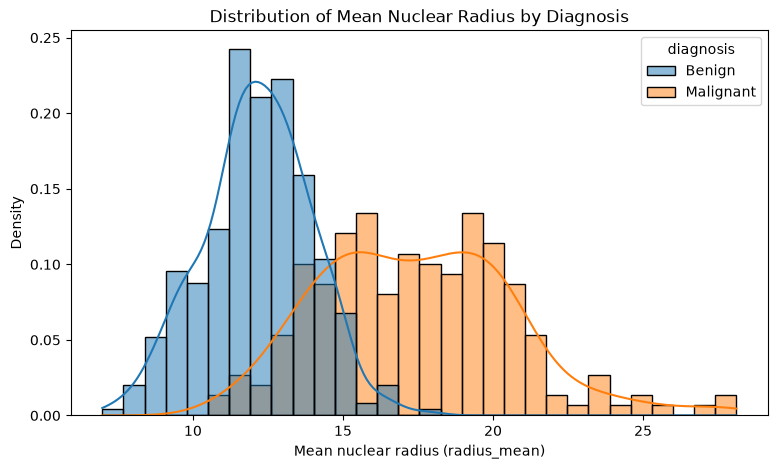

In [10]:
# Compare the radius distributions using density so unequal group sizes do not dominate the plot.
benign = df.loc[df["diagnosis"] == "Benign", "radius_mean"]
malignant = df.loc[df["diagnosis"] == "Malignant", "radius_mean"]

plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="radius_mean", hue="diagnosis", stat="density",
             common_norm=False, kde=True, bins=30)
plt.title("Distribution of Mean Nuclear Radius by Diagnosis")
plt.xlabel("Mean nuclear radius (radius_mean)")
plt.ylabel("Density")
plt.show()

Malignant samples generally have larger mean nuclear radii and greater variability than benign samples. The distributions overlap, indicating that some samples have similar radius measurements despite different diagnoses.

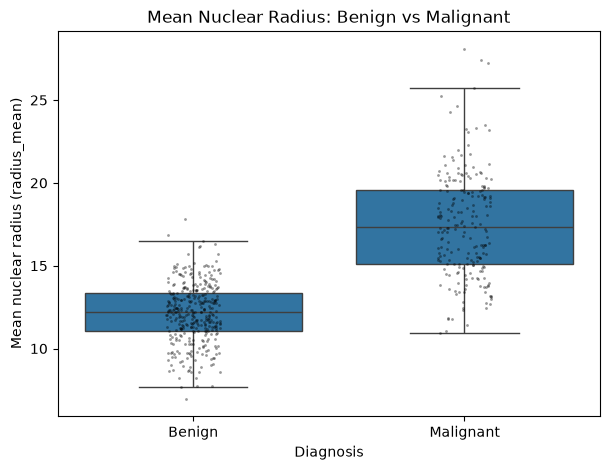

In [11]:
# Compare medians and spread, with individual points showing where the groups overlap.
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="diagnosis", y="radius_mean", showfliers=False)
sns.stripplot(data=df, x="diagnosis", y="radius_mean", color="black", size=2, alpha=0.4)
plt.title("Mean Nuclear Radius: Benign vs Malignant")
plt.xlabel("Diagnosis")
plt.ylabel("Mean nuclear radius (radius_mean)")
plt.show()

Malignant samples have a higher median mean nuclear radius and a wider spread than benign samples. The overlapping values show that mean nuclear radius does not completely separate the two groups.

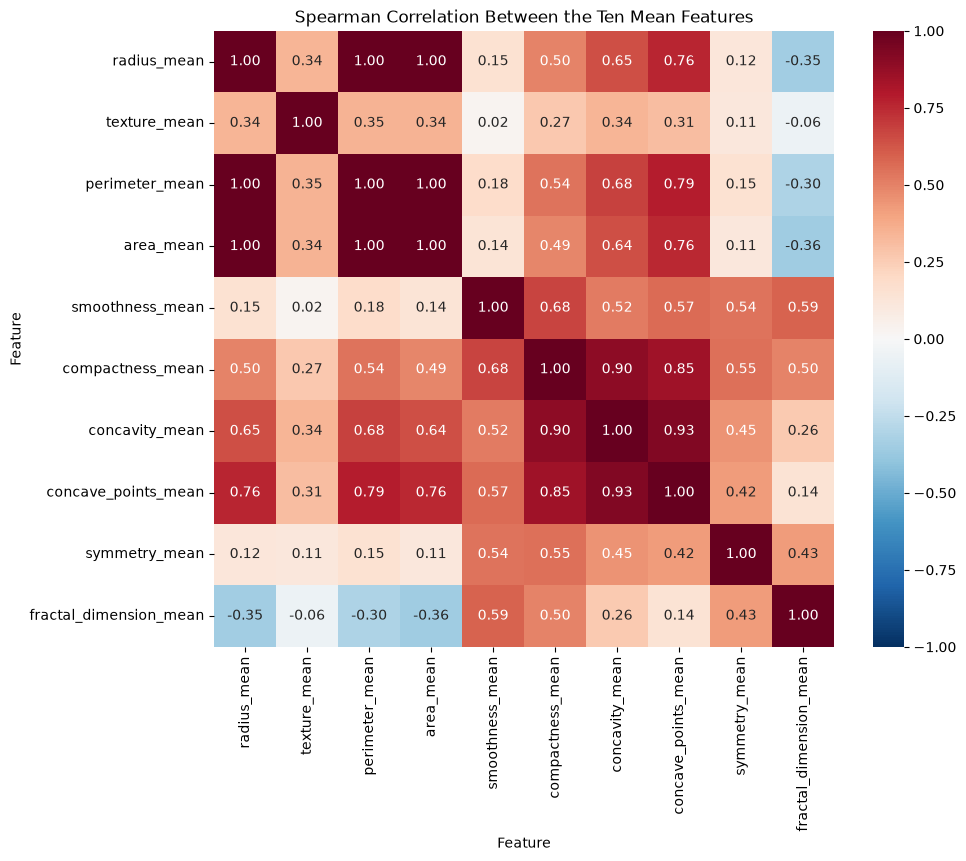

In [12]:
# Use Spearman correlation to see which features rank samples similarly.
corr = df[mean_cols].corr(method="spearman")
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Spearman Correlation Between the Ten Mean Features")
plt.xlabel("Feature")
plt.ylabel("Feature")
plt.show()

**Heatmap:** Mean radius, mean perimeter, and mean area had the strongest positive Spearman correlations. All three pairwise coefficients round to 1.00 on the heatmap, indicating that samples ranked almost identically across these size measurements. Mean concavity and mean concave points also had a strong positive correlation (0.93).

**Best chart for the research question**

The boxplot best supports my research question because it compares mean nuclear radius directly between benign and malignant samples on the same scale. Malignant samples had a higher median (17.33 vs. 12.20) and a wider spread, although individual values overlapped.

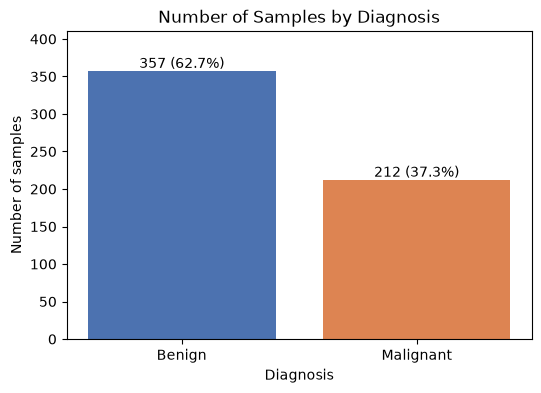

In [13]:
# Show the difference in sample counts between the two diagnosis groups.
plt.figure(figsize=(6, 4))
bars = plt.bar(counts.index.astype(str), counts.values, color=["#4C72B0", "#DD8452"])
plt.bar_label(bars, labels=[f"{n} ({n/len(df):.1%})" for n in counts.values])
plt.title("Number of Samples by Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Number of samples")
plt.ylim(0, counts.max() * 1.15)
plt.show()

**Bar chart:** Benign samples outnumber malignant ones, 357 (62.7%) to 212 (37.3%). The groups are unequal in size, but both are large enough for a reliable comparison of means. This split reflects how the samples were collected, not how common malignant masses are in the general population.

## Task 5: Hypothesis test

- **Null hypothesis ($H_0$)** — The population mean nuclear radius is equal for malignant and benign samples ($\mu_M = \mu_B$).
- **Alternative hypothesis ($H_1$)** — The population mean nuclear radius differs between the two groups ($\mu_M \neq \mu_B$).
- **Test:** two-sided Welch's two-sample t-test, α = 0.05.

**Assumptions.** Welch’s t-test does not assume equal variances, which matters here because the malignant group’s variance is about 3.2 times the benign group’s. It does assume independent observations; this depends on how the data were collected, and unique IDs alone cannot confirm it. Both groups are large (212 malignant, 357 benign), so the comparison of means is robust to the moderate skew in the data.

In [14]:
# Compare group means without assuming equal variances.
print("Variance ratio (M/B):", round(malignant.var() / benign.var(), 2))

t_stat, p_value = stats.ttest_ind(malignant, benign, equal_var=False)
print(f"t = {t_stat:.3f}, p = {p_value:.3e}")
print("Reject H0" if p_value < 0.05 else "Fail to reject H0")

Variance ratio (M/B): 3.24
t = 22.209, p = 1.684e-64
Reject H0


In [15]:
# Estimate the malignant-minus-benign mean difference and its 95% confidence interval.
res = stats.ttest_ind(malignant, benign, equal_var=False)
ci = res.confidence_interval(0.95)
diff = malignant.mean() - benign.mean()
print(f"Mean difference = {diff:.3f}, 95% CI {ci.low:.3f} to {ci.high:.3f}")

Mean difference = 5.316, 95% CI 4.845 to 5.787


Malignant samples had a higher average mean nuclear radius than benign samples (17.46 versus 12.15). Welch’s two-sample t-test found a statistically significant difference, t = 22.209, p = 1.684 × 10⁻⁶⁴. At α = 0.05, we reject the null hypothesis of equal population means.

The estimated mean difference was 5.316, with a 95% confidence interval from 4.845 to 5.787. These findings support an association between diagnosis and mean nuclear radius in this dataset. They do not establish causation or demonstrate that radius alone is sufficient for diagnosis.

## Task 6: Notebook summary

I analyzed 569 samples to see whether mean nuclear radius differed between benign and malignant diagnoses. Malignant samples had a higher average mean nuclear radius than benign samples (17.46 vs. 12.15). Welch’s t-test showed a statistically significant difference (\(t = 22.21\), \(p < 0.001\)), with a 95% confidence interval of 4.85–5.79 for the mean difference. I was surprised that mean radius, perimeter, and area ranked samples almost identically, with pairwise Spearman correlations that rounded to 1.00. One challenge was that the data file had no header row, so I built the 32 column names using wdbc.names. The groups’ radius measurements overlapped, so radius alone could not distinguish every benign sample from every malignant sample.